# FFM_3_7 — 完整 STL + 逐顶点 RFF → 可训练三角面编码 → 面邻接图 → 每耳 z

这版让**全部原始三角面的三个顶点及其 RFF**进入可训练网络；不随机采点，不裁耳、不截颈、不简化 mesh。
它读取与 3_6 相同的 `sonicom_full_meshes.zip`，保留每个人全部 15.7–90.5 万个面。

```text
全部 STL 三角面（原 float32 坐标，mm）
 → 每个顶点：保留原始 xyz + 耳道相对坐标的 RFF（不先求全网格均值）
 → 可训练的共享 corner MLP：逐顶点特征 + 面法向 + 真实面积 + 相对耳道位置
 → 三层共享边 face graph message passing（完整 CSR 邻接；非流形边不截断）
 → 网络内部的全头面积均值 / 最大值 + 多尺度软耳道读出
 → 小 MLP 输出头 → 训练 z 的全部有效主成分 → 5952 维 z → 冻结的 FFM26 decoder
```

**仍有 MLP**：它是面片编码器和最后的输出头；整体模型是网格图网络，不是“2569 维手工描述符 → MLP”。
soft readout 使用全部面，没有硬裁剪；全头读出始终保留远离耳道的表面。CSR 图由 STL 中精确重复的坐标推断共享边，
只用于建立邻接，不替换任何原始顶点、不焊接或移动输入几何。

**RFF 用法**：四个尺度 `σ=[0.02, 0.1, 0.5, 2.0] rad/mm`，每尺度 16 个随机三维波向量，
共 64 个频率 / 128 个 sin-cos 特征，固定 `RFF_SEED=37`；全部受试者/顶点共享同一组频率。
相位是 `(vertex_mm - canal_mm) @ K.T`，**不再乘 2π，也不使用除以 100 后的数值**。
右耳顶点和耳道一起反射；原始 xyz（固定除以 100）和原有几何特征一起保留，默认每 corner 输入 144 维。
RFF 支路除以 √64，使平方范数为 1；频率矩阵作为模型 buffer 保存到 checkpoint。
它在分块的 forward 内逐顶点计算，之后才进可训练 MLP；没有预先将整张网格压成 RFF 均值描述符。
尺度是可调默认值，并非已经验证的最优值；频率高低不等于声学 Hz。
`USE_RFF=False` 可作同结构对照，请为不同配置使用独立 OUT_DIR。

**算力**：针对用户的 G4 / RTX Pro 6000，自动读取实际显存，默认 width=64、graph blocks=3。
batch 是一只耳的完整 mesh；通过梯度累积形成小批次。分块和 activation checkpointing 改变计算方式，**不减少面数**。
Cell 8 在一张真实完整网格上做 forward/backward、检查最后一个分块、报告显存和耗时；OOM 应调小 `CHUNK_FACES`，
或降低 `WIDTH`，不要删面。初次 CSR 缓存构建会花时间，进度每人输出，缓存只放 Colab 本地盘。

**数据/评价**：same split seed=0；131 train / 33 val / 36 locked test，两耳按人绑定。
输入真实尺寸不按人归一化；固定除以 100 mm / 5 mm 只是数值单位变换。右耳整个 mesh 在网络内反射到左耳框架，并修正法向。
目标与 3_6 一样：训练集全部有效 PCs（通常 261，能重构全部训练 z，不是旧版的 64-PC 截断）。
每个 epoch 输出 train optimization loss、固定训练 probe 的 R²、完整验证 R² / pooled dB；probe **不是整个训练集**。
按验证 pooled dB 选 best epoch；SEEDS 默认 `[0]`，打乱目标对照是单独开关，默认关闭以减少完整 mesh 的运行时间。
报告人群 HRTF 均值、decoded mean z、oracle train-span projection 和 AE 重建。
已有 3_6 `results.json` 时，只有同一 split / source / baseline 核对通过才显示它作为历史对照。

**运行**：沿顺序 Run all。`RUN_TRAIN=True`、`RUN_TEST=False`。只需上传这一份 notebook；模型代码已内嵌。
Drive 文件保持 3_6 的位置：`ELEC5020/SONICOM/sonicom_full_meshes.zip`、`ELEC5020/SONICOM.zip`、
`HRTF_Checkpoints/FFM26_best.pth`、`HRTF_Checkpoints/mesh2z_sonicom_latents_v1.npz`。
输出保存在 `HRTF_Checkpoints/mesh2z_direct_graph_rff_v1`；中断后重跑可续训，EPOCHS / 优化 / RFF 配置改变时用新的 OUT_DIR。
`SMOKE_N` 只减少受试者数量，不减少任何人的三角面。正式运行保持 None。

**结论边界**：这是新的学习式完整网格实验，不保证优于 ridge；一个模型的失败仍不能证明全部几何方法失败。
完整源仍是 SONICOM 的 preprocessed STL，整理方已平滑、截断、去发；耳道来自仿真 ReceiverPosition。
网络最后仍须汇总可变大小的输入，有限隐层不是原 mesh 的可逆编码。36 人不参与拟合、模型选择或默认评分，
NPZ 的整体反序列化不应被误写为“测试 z 从未加载”。最终测试与 3_5 / 3_6 共用一次性标记。

技术参考：[Fourier feature mapping](https://bmild.github.io/fourfeat/index.html)、
[PyTorch activation checkpointing](https://docs.pytorch.org/docs/stable/checkpoint)。


In [ ]:
# Cell 0 — 环境 / 可核对的本地副本
import os, sys, io, json, csv, zipfile, hashlib, time, math, copy, shutil, gc
from pathlib import Path
import numpy as np
import torch
IN_COLAB = 'google.colab' in sys.modules
MESH_ZIP_SHA256 = 'a73401a12d92643d9c6c80a66cb443e9983b4880d53b78924fece42f7c124f8d'
AE_SHA256 = 'ea3c4a5f667ba30dafb0ff4167bcfffa8d4a738eec39146e17f7ada7ad4a5108'
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(1 << 24), b''): h.update(b)
    return h.hexdigest()
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    import importlib.util, subprocess
    if importlib.util.find_spec('healpy') is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'healpy'])
    SAVE_DIR = '/content/drive/MyDrive/HRTF_Checkpoints'
    LOCAL = '/content/ffm37_local'; os.makedirs(LOCAL, exist_ok=True)
    PATHS = dict(ckpt=f'{SAVE_DIR}/FFM26_best.pth', mesh_latent=f'{SAVE_DIR}/mesh2z_sonicom_latents_v1.npz',
                 meshes='/content/drive/MyDrive/ELEC5020/SONICOM/sonicom_full_meshes.zip',
                 sonicom='/content/drive/MyDrive/ELEC5020/SONICOM.zip')
    def stage(src, expected=None):
        assert os.path.isfile(src), src
        src_hash = expected or sha256_file(src)
        dst = os.path.join(LOCAL, os.path.basename(src))
        if not os.path.isfile(dst) or sha256_file(dst) != src_hash:
            t0 = time.time(); print(f'复制 {os.path.basename(src)}', flush=True)
            shutil.copy2(src, dst + '.part'); os.replace(dst + '.part', dst)
            print(f'  {time.time()-t0:.0f}s', flush=True)
        assert sha256_file(dst) == src_hash, f'复制哈希不匹配：{dst}'
        return dst
    PATHS['ckpt'] = stage(PATHS['ckpt'], AE_SHA256)
    PATHS['meshes'] = stage(PATHS['meshes'], MESH_ZIP_SHA256)
    PATHS['mesh_latent'] = stage(PATHS['mesh_latent'])
    OUT_DIR = f'{SAVE_DIR}/mesh2z_direct_graph_rff_v1'
else:
    H = os.path.expanduser('~/Documents'); R = f'{H}/26S2/ELEC5021/hrtf-GitHub'
    SAVE_DIR = f'{R}/mesh2z/output'
    LOCAL = os.environ.get('FFM37_LOCAL', f'{SAVE_DIR}/ffm37_local')
    PATHS = dict(ckpt=os.environ.get('FFM26_CKPT', f'{R}/results/FFM26_best.pth'),
                 mesh_latent=f'{R}/mesh2z/output/mesh2z_sonicom_latents_v1.npz',
                 meshes=f'{H}/26S1/ELEC5020/SONICOM/sonicom_full_meshes.zip',
                 sonicom=f'{H}/26S1/ELEC5020/SONICOM')
    OUT_DIR = os.environ.get('FFM37_OUT', f'{SAVE_DIR}/mesh2z_direct_graph_rff_v1')
os.makedirs(LOCAL, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)
for k,p in PATHS.items(): print(k, p); assert os.path.exists(p), p
assert sha256_file(PATHS['meshes']) == MESH_ZIP_SHA256
assert sha256_file(PATHS['ckpt']) == AE_SHA256
LATENT_SHA = sha256_file(PATHS['mesh_latent'])
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
if device.type == 'cuda':
    props = torch.cuda.get_device_properties(0); GPU_GB = props.total_memory / 2**30
    print(f'实际 GPU：{props.name} | {GPU_GB:.1f} GiB | torch {torch.__version__}')
else:
    GPU_GB = 0.; print('CPU：可做检查；完整数据训练建议在 Colab GPU 运行。')


Mounted at /content/drive
复制 FFM26_best.pth
  5s
复制 sonicom_full_meshes.zip
  57s
复制 mesh2z_sonicom_latents_v1.npz
  0s
ckpt /content/ffm37_local/FFM26_best.pth
mesh_latent /content/ffm37_local/mesh2z_sonicom_latents_v1.npz
meshes /content/ffm37_local/sonicom_full_meshes.zip
sonicom /content/drive/MyDrive/ELEC5020/SONICOM.zip
实际 GPU：NVIDIA RTX PRO 6000 Blackwell Server Edition | 95.0 GiB | torch 2.11.0+cu130


In [ ]:
# Cell 1 — 冻结配置；自动分块不改变输入面数
CFG = dict(SPLIT_SEED=0, VAL_FRAC=.20, SMOKE_N=None, DID=2,
           WIDTH=64, GRAPH_BLOCKS=3, HEAD_WIDTH=128, DROPOUT=.1,
           CHUNK_FACES=(65536 if GPU_GB >= 40 else 16384), CHECKPOINT_BLOCKS=True,
           SOFT_RADII_MM=(15.,40.,100.),
           USE_RFF=True, RFF_FEATURES_PER_SCALE=16, RFF_SIGMAS_RAD_PER_MM=(.02,.1,.5,2.), RFF_SEED=37,
           SEEDS=[0], EPOCHS=100, LR=3e-4, LR_MIN=1e-5, WD=1e-3,
           GRAD_ACCUM_EARS=4, GRAD_CLIP=1., EVAL_EVERY=1, TRAIN_PROBE_SUBJECTS=8,
           NOTCH_HZ=(6000,12000), RUN_TRAIN=True, RUN_SHUFFLED=False, RUN_TEST=False,
           CHECK_ACTUAL_MESH_GRAD=True, N_BOOT=2000)
if not IN_COLAB and os.environ.get('FFM37_SMOKE_N'):
    CFG.update(SMOKE_N=int(os.environ['FFM37_SMOKE_N']), EPOCHS=int(os.environ.get('FFM37_EPOCHS','1')))
print(json.dumps(CFG, indent=1))


{
 "SPLIT_SEED": 0,
 "VAL_FRAC": 0.2,
 "SMOKE_N": null,
 "DID": 2,
 "WIDTH": 64,
 "GRAPH_BLOCKS": 3,
 "HEAD_WIDTH": 128,
 "DROPOUT": 0.1,
 "CHUNK_FACES": 65536,
 "CHECKPOINT_BLOCKS": true,
 "SOFT_RADII_MM": [
  15.0,
  40.0,
  100.0
 ],
 "USE_RFF": true,
 "RFF_FEATURES_PER_SCALE": 16,
 "RFF_SIGMAS_RAD_PER_MM": [
  0.02,
  0.1,
  0.5,
  2.0
 ],
 "RFF_SEED": 37,
 "SEEDS": [
  0
 ],
 "EPOCHS": 100,
 "LR": 0.0003,
 "LR_MIN": 1e-05,
 "WD": 0.001,
 "GRAD_ACCUM_EARS": 4,
 "GRAD_CLIP": 1.0,
 "EVAL_EVERY": 1,
 "TRAIN_PROBE_SUBJECTS": 8,
 "NOTCH_HZ": [
  6000,
  12000
 ],
 "RUN_TRAIN": true,
 "RUN_SHUFFLED": false,
 "RUN_TEST": false,
 "CHECK_ACTUAL_MESH_GRAD": true,
 "N_BOOT": 2000
}


In [ ]:
# Cell 2 — 完整三角面网络（self-contained；与 fullmesh_graph.py 相同）
CORE_SHA256 = '19fbf7c162151f6dc131b2ed8ec1cfb74b576a5d7213b80d29b2f7d130655616'
"""All-face mesh encoder for FFM_3_7. Only NumPy and PyTorch are required.

No crop, point sampling, decimation, or precomputed global descriptor. Each STL face's
three coordinates, augmented with per-vertex RFF, enter a learned corner encoder.
CSR adjacency retains every shared-edge
connection, including non-manifold edge fans. Chunking and checkpointing retain all faces.
"""
import hashlib
import math
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint

GRAPH_VERSION = 'ffm37-all-faces-csr-v1'


def read_stl_bytes(b):
    if len(b) < 84:
        raise ValueError('STL shorter than its binary header')
    n = int(np.frombuffer(b, '<u4', count=1, offset=80)[0])
    if n == 0 or len(b) != 84 + 50 * n:
        raise ValueError(f'Invalid binary STL: {n} faces, {len(b)} bytes')
    dt = np.dtype([('n', '<f4', 3), ('v', '<f4', (3, 3)), ('attr', '<u2')])
    V = np.frombuffer(b, dt, count=n, offset=84)['v'].copy()
    if not np.isfinite(V).all():
        raise ValueError('Non-finite source vertex')
    return V


def face_adjacency(V):
    """CSR face graph by exact source coordinates; geometry and all face IDs are retained.

    Exact coordinate welding is used ONLY to discover adjacency. It does not replace V.
    Signed zeros denote the same point. Other nearby-but-distinct coordinates are not welded.
    Multiple faces on an edge are connected as a fan clique, without truncating their degree.
    """
    n = len(V)
    xyz = np.ascontiguousarray(V.reshape(-1, 3), dtype=np.float32).copy()
    xyz[xyz == 0] = 0.0
    key = xyz.view(np.dtype((np.void, 12))).ravel()
    _, inv = np.unique(key, return_inverse=True)
    tri = inv.reshape(n, 3)
    edge = np.sort(np.concatenate([tri[:, [0, 1]], tri[:, [1, 2]], tri[:, [2, 0]]]), axis=1)
    owner = np.tile(np.arange(n, dtype=np.int64), 3)
    order = np.lexsort((edge[:, 1], edge[:, 0]))
    edge, owner = edge[order], owner[order]
    starts = np.r_[0, np.flatnonzero(np.any(edge[1:] != edge[:-1], axis=1)) + 1]
    ends = np.r_[starts[1:], len(edge)]
    counts = ends - starts
    ix = starts[counts == 2]
    a, b = owner[ix], owner[ix + 1]
    sources, targets = [a, b], [b, a]
    for start, end in zip(starts[counts > 2], ends[counts > 2]):
        faces = np.unique(owner[start:end])
        aa, bb = np.meshgrid(faces, faces, indexing='ij')
        use = aa != bb
        sources.append(aa[use]); targets.append(bb[use])
    src, dst = np.concatenate(sources), np.concatenate(targets)
    keep = src != dst
    pairs = np.unique(np.stack([src[keep], dst[keep]], 1), axis=0)
    ptr = np.r_[0, np.cumsum(np.bincount(pairs[:, 0], minlength=n))].astype(np.int64)
    nbr = pairs[:, 1].astype(np.int32)
    assert len(ptr) == n + 1 and ptr[-1] == len(nbr)
    stats = dict(n_faces=n, n_exact_vertices=int(inv.max()) + 1,
                 n_directed_neighbors=len(nbr), n_boundary_edges=int(np.count_nonzero(counts == 1)),
                 n_nonmanifold_edges=int(np.count_nonzero(counts > 2)),
                 n_isolated_faces=int(np.count_nonzero(np.diff(ptr) == 0)),
                 max_degree=int(np.diff(ptr).max()), graph_version=GRAPH_VERSION)
    return ptr, nbr, stats


def prepare_graph_cache(V, source_sha256, cache_root):
    """CPU disk cache of exact triangle coordinates + CSR; never a learned-feature cache."""
    root = Path(cache_root) / (source_sha256[:20] + '_' + GRAPH_VERSION)
    root.mkdir(parents=True, exist_ok=True)
    meta_path = root / 'meta.json'
    import json
    if meta_path.exists():
        meta = json.loads(meta_path.read_text())
        assert meta['source_sha256'] == source_sha256 and meta['graph_version'] == GRAPH_VERSION
        vv = np.load(root / 'triangles.npy', mmap_mode='r')
        pp = np.load(root / 'ptr.npy', mmap_mode='r')
        nn_ = np.load(root / 'nbr.npy', mmap_mode='r')
        assert vv.shape == V.shape and vv.dtype == V.dtype
        assert np.array_equal(vv, V), 'Geometry cache differs from current verified STL'
        assert len(pp) == len(V) + 1 and pp[-1] == len(nn_)
        return root, meta
    ptr, nbr, stats = face_adjacency(V)
    for name, a in [('triangles', V), ('ptr', ptr), ('nbr', nbr)]:
        tmp = root / (name + '.tmp.npy')
        np.save(tmp, a); tmp.replace(root / (name + '.npy'))
    meta = dict(stats, source_sha256=source_sha256)
    tmp = root / 'meta.tmp.json'; tmp.write_text(json.dumps(meta, indent=2)); tmp.replace(meta_path)
    return root, meta


class VertexRFF(nn.Module):
    """Fixed, shared Fourier augmentation of each 3D vertex; coordinates are in mm.

    Wavevectors are angular spatial frequencies in rad/mm: phase = p @ K.T,
    with NO extra 2*pi. All subjects/corners share K, saved as a state_dict buffer.
    This layer does not reduce the face/corner axes or replace the raw coordinates.
    """
    def __init__(self, features_per_scale=16, sigmas_rad_per_mm=(.02, .1, .5, 2.), seed=37):
        super().__init__()
        m = int(features_per_scale)
        sigmas = np.asarray(sigmas_rad_per_mm, dtype=np.float64)
        if m < 0 or sigmas.ndim != 1 or not len(sigmas) or not np.isfinite(sigmas).all() or (sigmas <= 0).any():
            raise ValueError('RFF needs non-negative feature count and finite positive scales')
        rng = np.random.default_rng(int(seed))
        K = np.concatenate([rng.standard_normal((m, 3)) * s for s in sigmas], axis=0).astype(np.float32)
        self.register_buffer('wavevectors_rad_per_mm', torch.from_numpy(K))
        self.feature_dim = 2 * len(K)
        self.amplitude = 1. / math.sqrt(len(K)) if len(K) else 1.

    def forward(self, positions_mm):
        if not self.feature_dim:
            return positions_mm.new_empty((*positions_mm.shape[:-1], 0))
        phase = positions_mm @ self.wavevectors_rad_per_mm.T
        # Keep total Fourier feature energy at one as the frequency count changes.
        return torch.cat([torch.cos(phase), torch.sin(phase)], -1) * self.amplitude


class CornerEncoder(nn.Module):
    def __init__(self, width, use_rff=True, rff_features_per_scale=16,
                 rff_sigmas_rad_per_mm=(.02, .1, .5, 2.), rff_seed=37):
        super().__init__()
        self.rff = VertexRFF(rff_features_per_scale if use_rff else 0, rff_sigmas_rad_per_mm, rff_seed)
        # Existing 13 geometric inputs + explicit raw xyz (3) + per-vertex RFF (128 by default).
        self.corner = nn.Sequential(nn.Linear(16 + self.rff.feature_dim, 32), nn.GELU(), nn.Linear(32, 32), nn.GELU())
        self.face = nn.Sequential(nn.Linear(74, width), nn.GELU(), nn.LayerNorm(width))

    def forward(self, V, canal, flip):
        # One ear frame for ALL source faces. Right reflection reverses face winding as well.
        Q = V * flip
        center = Q.mean(1)
        cross = torch.linalg.cross(Q[:, 1] - Q[:, 0], Q[:, 2] - Q[:, 0]) * flip.prod()
        area2 = cross.norm(dim=1)
        normal = cross / area2.clamp_min(1e-20)[:, None]
        rel = center - canal * flip
        geom = torch.cat([center / 100., rel / 100., normal, torch.log1p(area2 / 2)[:, None]], 1)
        # Fixed physical divisors, NOT per-person normalization. Every original corner enters.
        offsets = (Q - center[:, None]) / 5.
        positions_mm = Q - canal * flip
        x = torch.cat([geom[:, None].expand(-1, 3, -1), offsets, Q / 100., self.rff(positions_mm)], -1)
        h = self.corner(x)
        return self.face(torch.cat([h.mean(1), h.amax(1), geom], 1))


class FaceGraphBlock(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.mix = nn.Sequential(nn.Linear(3 * width, width), nn.GELU(), nn.Linear(width, width))
        self.norm = nn.LayerNorm(width)

    def forward(self, h, neighbors, offsets, ids):
        # Empty bags (boundary/isolated faces) produce zero; no faces are dropped.
        near = F.embedding_bag(neighbors, h, offsets, mode='mean', include_last_offset=True)
        own = h.index_select(0, ids)
        return self.norm(own + self.mix(torch.cat([own, near, near - own], 1)))


class FullMeshGraphRegressor(nn.Module):
    def __init__(self, out_dim, width=64, n_blocks=3, head_width=128, dropout=.1,
                 chunk_faces=32768, checkpoint_blocks=True, soft_radii_mm=(15., 40., 100.),
                 use_rff=True, rff_features_per_scale=16, rff_sigmas_rad_per_mm=(.02, .1, .5, 2.), rff_seed=37):
        super().__init__()
        self.encoder = CornerEncoder(width, use_rff, rff_features_per_scale, rff_sigmas_rad_per_mm, rff_seed)
        self.blocks = nn.ModuleList([FaceGraphBlock(width) for _ in range(n_blocks)])
        self.chunk_faces = int(chunk_faces)
        self.checkpoint_blocks = bool(checkpoint_blocks)
        self.soft_radii_mm = tuple(map(float, soft_radii_mm))
        d = (2 + len(self.soft_radii_mm)) * width + 7
        self.head = nn.Sequential(nn.Linear(d, head_width), nn.GELU(), nn.Dropout(dropout),
                                  nn.Linear(head_width, out_dim))
        nn.init.normal_(self.head[-1].weight, std=1e-3)
        nn.init.zeros_(self.head[-1].bias)
        self.last_n_faces = None

    def _run(self, fn, *args):
        if self.training and torch.is_grad_enabled() and self.checkpoint_blocks:
            return checkpoint(fn, *args, use_reentrant=False, preserve_rng_state=False)
        return fn(*args)

    def forward(self, V, ptr_cpu, neighbors, canal, side=0):
        n = len(V)
        if n == 0 or len(ptr_cpu) != n + 1:
            raise ValueError('Full face graph shape mismatch')
        flip = V.new_tensor([1., -1. if int(side) else 1., 1.])
        chunks = [(a, min(a + self.chunk_faces, n)) for a in range(0, n, self.chunk_faces)]
        self.last_n_faces = sum(b - a for a, b in chunks)
        assert self.last_n_faces == n, 'A tail chunk was omitted'
        h = torch.cat([self._run(self.encoder, V[a:b], canal, flip) for a, b in chunks], 0)
        for block in self.blocks:
            out = []
            for a, b in chunks:
                lo, hi = int(ptr_cpu[a]), int(ptr_cpu[b])
                offsets = torch.as_tensor(ptr_cpu[a:b + 1] - lo, dtype=torch.long, device=V.device)
                ids = torch.arange(a, b, device=V.device)
                out.append(self._run(block, h, neighbors[lo:hi], offsets, ids))
            h = torch.cat(out, 0)
        # These reductions are INSIDE the learned network, after every face has been encoded.
        Q = V * flip
        center = Q.mean(1)
        area = .5 * torch.linalg.cross(Q[:, 1] - Q[:, 0], Q[:, 2] - Q[:, 0]).norm(dim=1)
        total = area.sum().clamp_min(1e-20)
        pools = [(h * (area / total)[:, None]).sum(0), h.amax(0)]
        dist2 = ((center - canal * flip) ** 2).sum(1)
        for radius in self.soft_radii_mm:
            w = area * torch.exp(-.5 * dist2 / radius ** 2)
            pools.append((h * (w / w.sum().clamp_min(1e-20))[:, None]).sum(0))
        # Both global reductions include the entire head: soft ear readouts are not hard crops.
        bounds = Q.reshape(-1, 3).amax(0) - Q.reshape(-1, 3).amin(0)
        physical = torch.cat([canal * flip / 100., bounds / 100., torch.log1p(total)[None] / 10.])
        return self.head(torch.cat([*pools, physical]))


def to_device_mesh(V, ptr, nbr, device):
    # Copies keep read-only memory mapped arrays out of torch's writable storage contract.
    return (torch.from_numpy(np.array(V, copy=True)).to(device), np.array(ptr, copy=True),
            torch.from_numpy(np.array(nbr, dtype=np.int64, copy=True)).to(device))


In [ ]:
# Cell 3 — 受试者、完整 STL 来源、局部 CSR 缓存；不接触任何拟合目标
L = np.load(PATHS['mesh_latent'], allow_pickle=False)
ALL_DEV = list(map(str,L['eval_sids'])); LOCKED = list(map(str,L['locked_sids']))
assert len(ALL_DEV)==164 and len(LOCKED)==36 and not(set(ALL_DEV)&set(LOCKED))
SID_INDEX = {str(s):i for i,s in enumerate(L['sid'])}
AE_PART = dict(zip(map(str,L['sid']),map(str,L['ae_part'])))
assert all(AE_PART[s] in ('train','val') for s in ALL_DEV) and all(AE_PART[s]=='test' for s in LOCKED)
DEV = ALL_DEV[:CFG['SMOKE_N']] if CFG['SMOKE_N'] else ALL_DEV
assert len(DEV)>=5, 'SMOKE_N 至少 5 人；仍然保留每人的全部面'
ZF = zipfile.ZipFile(PATHS['meshes'])
MAN = {'SON_'+r['subject']:r for r in csv.DictReader(io.TextIOWrapper(ZF.open('sonicom_full_meshes/manifest_full.csv'),encoding='utf-8'))}
assert set(MAN)==set(ALL_DEV)|set(LOCKED) and len(MAN)==200
assert all(MAN[s]['partition']=='dev' for s in ALL_DEV) and all(MAN[s]['partition']=='locked' for s in LOCKED)
PACK_INFO = json.loads(ZF.read('sonicom_full_meshes/PACK_INFO.json'))
print(PACK_INFO['source'])
CACHE_ROOT = os.path.join(LOCAL,'mesh_graphs'); GRAPH_PATHS = {}; GRAPH_META = {}
def prepare_subject(s):
    if s in GRAPH_PATHS: return GRAPH_PATHS[s]
    r=MAN[s]; b=ZF.read('sonicom_full_meshes/'+r['stl_file'])
    assert hashlib.sha256(b).hexdigest()==r['stl_sha256'], f'{s}: STL 哈希不匹配'
    V=read_stl_bytes(b); assert len(V)==int(r['n_tris'])
    p,meta=prepare_graph_cache(V,r['stl_sha256'],CACHE_ROOT)
    GRAPH_PATHS[s]=p; GRAPH_META[s]=meta
    return p
def load_subject(s):
    p=prepare_subject(s)
    V=np.load(p/'triangles.npy',mmap_mode='r'); ptr=np.load(p/'ptr.npy',mmap_mode='r'); nbr=np.load(p/'nbr.npy',mmap_mode='r')
    assert len(V)==int(MAN[s]['n_tris']) and ptr[-1]==len(nbr)
    canals=np.array([[float(MAN[s][f'ear_{sd}_{a}_mm']) for a in 'xyz'] for sd in ('left','right')],np.float32)
    return (*to_device_mesh(V,ptr,nbr,device),torch.from_numpy(canals).to(device))
t0=time.time()
for i,s in enumerate(DEV,1):
    prepare_subject(s); st=GRAPH_META[s]
    print(f'[{i}/{len(DEV)}] {s}: {st["n_faces"]:,} faces, {st["n_directed_neighbors"]:,} 邻接, '
          f'{st["n_nonmanifold_edges"]} 非流形边，累计 {time.time()-t0:.0f}s',flush=True)
print('没有裁剪、采样或减面。CSR 缓存只含原三角面坐标与连接。')


SONICOM synthetic/PXXXX/SYNTHETIC_HRTF/PXXXX_preprocessed.stl (Frankfurt-aligned, beheaded, smoothed, hair removed by the SONICOM curators; not the raw 3DSCAN)
[1/164] SON_P0002: 393,302 faces, 1,179,906 邻接, 0 非流形边，累计 1s
[2/164] SON_P0003: 778,262 faces, 2,334,786 邻接, 0 非流形边，累计 4s
[3/164] SON_P0004: 241,686 faces, 724,950 邻接, 7 非流形边，累计 4s
[4/164] SON_P0005: 817,116 faces, 2,451,348 邻接, 0 非流形边，累计 7s
[5/164] SON_P0006: 472,638 faces, 1,417,914 邻接, 0 非流形边，累计 8s
[6/164] SON_P0007: 457,212 faces, 1,371,636 邻接, 0 非流形边，累计 9s
[7/164] SON_P0009: 389,972 faces, 1,169,916 邻接, 0 非流形边，累计 11s
[8/164] SON_P0010: 300,163 faces, 900,484 邻接, 0 非流形边，累计 11s
[9/164] SON_P0014: 399,984 faces, 1,199,952 邻接, 0 非流形边，累计 13s
[10/164] SON_P0015: 282,166 faces, 846,490 邻接, 0 非流形边，累计 13s
[11/164] SON_P0016: 314,304 faces, 942,912 邻接, 0 非流形边，累计 14s
[12/164] SON_P0019: 363,074 faces, 1,089,224 邻接, 2 非流形边，累计 15s
[13/164] SON_P0020: 256,150 faces, 768,458 邻接, 1 非流形边，累计 16s
[14/164] SON_P0024: 426,162 faces, 1,278,486 邻

In [ ]:
# Cell 4 — 网络结构检查：所有面、最后一个分块、非流形边、分块等价、梯度
def mesh_network_selfcheck():
    rng=np.random.default_rng(37)
    # 11 面含尾块；前三面共享同一条非流形边，其余是独立面。
    V=rng.normal(size=(11,3,3)).astype(np.float32)
    V[:3,:2]=np.array([[0,0,0],[1,0,0]],np.float32)
    ptr,nbr,st=face_adjacency(V)
    for i in range(3): assert set(nbr[ptr[i]:ptr[i+1]])==({0,1,2}-{i})
    torch.manual_seed(37)
    a=FullMeshGraphRegressor(7,width=8,n_blocks=2,dropout=0,chunk_faces=3,checkpoint_blocks=True)
    b=FullMeshGraphRegressor(7,width=8,n_blocks=2,dropout=0,chunk_faces=99,checkpoint_blocks=False)
    b.load_state_dict(a.state_dict())
    x=torch.tensor(V,requires_grad=True); canal=torch.tensor([.1,.2,.3]); ni=torch.tensor(nbr.astype(np.int64))
    ya=a(x,ptr,ni,canal,side=0); yb=b(x,ptr,ni,canal,side=0)
    torch.testing.assert_close(ya,yb,rtol=2e-5,atol=2e-6)
    ya.square().sum().backward()
    assert a.last_n_faces==len(V) and torch.isfinite(x.grad).all()
    assert x.grad[-1].abs().sum()>0, '最后一张面没有进入可训练路径'
    perm=rng.permutation(len(V)); pp,nn_,_=face_adjacency(V[perm])
    a.eval(); b.eval()
    with torch.no_grad():
        y1=a(torch.tensor(V),ptr,ni,canal)
        y2=a(torch.tensor(V[perm]),pp,torch.tensor(nn_.astype(np.int64)),canal)
    torch.testing.assert_close(y1,y2,rtol=2e-5,atol=2e-6)
    # 每个 corner 的 RFF 保留其位置轴；同一 K 在不同模型随机种子下保持一致。
    positions=torch.tensor(V)-canal
    ff=a.encoder.rff(positions); K=a.encoder.rff.wavevectors_rad_per_mm
    assert ff.shape==(len(V),3,128)
    phase=positions@K.T
    torch.testing.assert_close(ff,torch.cat([phase.cos(),phase.sin()],-1)/math.sqrt(len(K)))
    torch.testing.assert_close(ff.square().sum(-1),torch.ones((len(V),3)))
    assert 'encoder.rff.wavevectors_rad_per_mm' in a.state_dict()
    assert a.encoder.rff.wavevectors_rad_per_mm.grad is None
    assert a.encoder.corner[0].weight.grad[:,16:].abs().sum()>0, 'RFF 支路没有进入学习路径'
    raw=FullMeshGraphRegressor(7,width=8,n_blocks=2,dropout=0,chunk_faces=3,use_rff=False)
    assert raw.encoder.corner[0].in_features==16 and raw.encoder.rff(positions).shape==(len(V),3,0)
    assert torch.isfinite(raw(torch.tensor(V),ptr,ni,canal)).all()
    print('小图自检通过：逐顶点 RFF/固定 buffer/支路梯度；非流形 fan 完整；分块等价；面顺序不影响输出；尾面有梯度。')
mesh_network_selfcheck()


小图自检通过：逐顶点 RFF/固定 buffer/支路梯度；非流形 fan 完整；分块等价；面顺序不影响输出；尾面有梯度。


In [ ]:
# Cell 5 — FFM26 模型定义：逐字复用 3_6；只作为冻结 decoder
# ==========================================================================
# Cell 2 - 模型定义（与 FFM_2_3 / FFM_2_6 逐字相同，构建时复制进来）
# ==========================================================================
import numpy as np
import torch
import torch.nn as nn
import healpy as hp


# ---------------------------------------------- spherical convolution
class OSLOConv(nn.Module):
    """Anisotropic convolution on HEALPix: each pixel plus its 8 neighbours, 9 independent weights."""
    def __init__(self, in_channels, out_channels, nside=16):
        super().__init__()
        self.npix = hp.nside2npix(nside)
        neighbors = hp.get_all_neighbours(nside, np.arange(self.npix))
        rf = np.concatenate([neighbors, np.arange(self.npix)[np.newaxis, :]], axis=0)
        rf[rf == -1] = self.npix
        self.register_buffer('neighborhood', torch.tensor(rf, dtype=torch.int64))
        self.weight = nn.Parameter(torch.empty(out_channels, in_channels, 9))
        self.bias = nn.Parameter(torch.empty(out_channels))
        nn.init.kaiming_uniform_(self.weight, a=np.sqrt(5))
        nn.init.zeros_(self.bias)

    def forward(self, x):
        B, C, _ = x.shape
        pad = torch.zeros(B, C, 1, device=x.device, dtype=x.dtype)
        g = torch.cat([x, pad], dim=2)[:, :, self.neighborhood]
        return torch.einsum('bcqn,ocq->bon', g, self.weight) + self.bias.view(1, -1, 1)


class OSLOResBlock(nn.Module):
    """Frequency-isolated residual block, operating on (B*F, C, N).
    * v2: ReLU -> GELU. HRTF log-magnitude is bipolar (negative means attenuation), so
      ReLU truncates the negative half; GELU is smooth, keeps negatives, and matches the fc layers."""
    def __init__(self, in_channels, out_channels, nside=16, num_groups=8):
        super().__init__()
        self.shortcut = (nn.Conv1d(in_channels, out_channels, 1)
                         if in_channels != out_channels else nn.Identity())
        self.conv1 = OSLOConv(in_channels, out_channels, nside)
        self.gn1 = nn.GroupNorm(num_groups, out_channels)
        self.conv2 = OSLOConv(out_channels, out_channels, nside)
        self.gn2 = nn.GroupNorm(num_groups, out_channels)
        self.act = nn.GELU()

    def forward(self, x):
        res = self.shortcut(x)
        out = self.act(self.gn1(self.conv1(x)))
        out = self.gn2(self.conv2(out))
        return self.act(out + res)


# ---------------------------------------------- per-dataset FiLM
class DatasetFiLM(nn.Module):
    """Learn one PER-FREQUENCY scale/shift curve for each dataset.

    ** Constraint 1: frequency only, NEVER direction.
      A per-frequency affine map is one EQ curve (93 dof per dataset). All it can absorb is
      "colouration common to the whole dataset and independent of direction" — loudspeaker and
      microphone response, equalisation convention, overall level. By construction it CANNOT
      express a direction-dependent difference, so population anatomy (ear-size distributions
      differ across databases) must still live in z. Contrast: subtracting a per-database mean
      over (frequency x direction) is 3072x93 dof, enough to remove the real population structure
      as well — exactly the wrong direction Craig pointed at. A factor of 3072 in expressive power.

    ** Constraint 2: centre across datasets.
      Without centring, log_gamma/beta learn a global EQ that cancels against the network's own
      output gain — a redundant degree of freedom. After the cross-database mean is removed FiLM
      expresses only RELATIVE differences; the absolute part stays in the network. Exactly the identity when num_datasets=1.
    """
    def __init__(self, num_datasets, num_bins):
        super().__init__()
        self.num_datasets = num_datasets
        self.log_gamma = nn.Parameter(torch.zeros(num_datasets, num_bins))
        self.beta = nn.Parameter(torch.zeros(num_datasets, num_bins))

    def params(self, dataset_id):
        lg = self.log_gamma - self.log_gamma.mean(0, keepdim=True)
        bt = self.beta - self.beta.mean(0, keepdim=True)
        return torch.exp(lg[dataset_id]).unsqueeze(-1), bt[dataset_id].unsqueeze(-1)

    def forward(self, x, dataset_id):
        g, b = self.params(dataset_id)
        return x * g + b

    def inverse(self, x, dataset_id):
        g, b = self.params(dataset_id)
        return (x - b) / g


# ---------------------------------------------- encoder / decoder

class Isolated_OSLO_Encoder(nn.Module):
    """Encode each frequency bin independently -> latent (B, F, latent_dim)"""
    def __init__(self, nside=16, latent_dim_per_freq=64):
        super().__init__()
        self.npix = hp.nside2npix(nside)
        self.latent_dim = latent_dim_per_freq
        self.enc1 = OSLOResBlock(1, 16, nside)
        self.enc2 = OSLOResBlock(16, 32, nside)
        self.fc_encode = nn.Sequential(
            nn.Flatten(), nn.Linear(32 * self.npix, 512), nn.GELU(),
            nn.Linear(512, self.latent_dim))

    def forward(self, x):
        B, F, N = x.shape
        z = self.fc_encode(self.enc2(self.enc1(x.reshape(B * F, 1, N))))
        return z.reshape(B, F, self.latent_dim)


class Conditioned_OSLO_Decoder(nn.Module):
    """FFM frequency-conditioned decoder + per-dataset FiLM on the output"""
    def __init__(self, nside=16, latent_dim_per_freq=64, freq_embed_dim=32,
                 num_datasets=1, num_bins=93):
        super().__init__()
        self.npix = hp.nside2npix(nside)
        self.latent_dim = latent_dim_per_freq
        self.freq_embed_dim = freq_embed_dim
        self.ffm_B = nn.Parameter(torch.randn(freq_embed_dim // 2))
        self.fc_decode = nn.Sequential(
            nn.Linear(self.latent_dim + freq_embed_dim, 512), nn.GELU(),
            nn.Linear(512, 32 * self.npix))
        self.dec1 = OSLOResBlock(32, 16, nside)
        self.dec_final = OSLOConv(16, 1, nside)
        self.film = DatasetFiLM(num_datasets, num_bins)

    def get_freq_embedding(self, num_freqs, device):
        f = torch.arange(num_freqs, device=device).float() / (num_freqs - 1)
        proj = 2 * np.pi * f.unsqueeze(1) * self.ffm_B.unsqueeze(0)
        return torch.cat([torch.sin(proj), torch.cos(proj)], dim=1)

    def forward(self, z, dataset_id=None):
        B, F, _ = z.shape
        fe = self.get_freq_embedding(F, z.device).unsqueeze(0).expand(B, -1, -1)
        h = torch.cat([z, fe], dim=-1).reshape(B * F, -1)
        h = self.fc_decode(h).reshape(B * F, 32, self.npix)
        out = self.dec_final(self.dec1(h)).reshape(B, F, self.npix)
        if dataset_id is not None:
            out = self.film(out, dataset_id)
        return out


class FFM_OSLO_Autoencoder(nn.Module):
    """One SHARED-parameter inverse FiLM at the encoder input — zero extra parameters.

    With FiLM on the decoder output only, the colouration stays in x, the encoder takes it in, and it
    lands in z — but z is exactly what the downstream geometry->latent stage needs. Output-side FiLM
    only makes the reconstruction loss line up; it does not clean z.

    Here     x_norm = (x - beta)/gamma        <- remove colouration
             z      = encoder(x_norm)
             out    = gamma * decoder(z) + beta   <- back to the original space, loss still on raw

    The SAME FiLM parameters are used. Together with centring this also kills the trivial degenerate
    direction "scale gamma up, scale the network down". Set tie_encoder_film=False to disable.
    """
    def __init__(self, nside=16, latent_dim_per_freq=64, freq_embed_dim=32,
                 num_datasets=1, num_bins=93, tie_encoder_film=True):
        super().__init__()
        self.encoder = Isolated_OSLO_Encoder(nside, latent_dim_per_freq)
        self.decoder = Conditioned_OSLO_Decoder(nside, latent_dim_per_freq,
                                                freq_embed_dim, num_datasets, num_bins)
        self.tie_encoder_film = tie_encoder_film

    def forward(self, x, dataset_id=None):
        if dataset_id is not None and self.tie_encoder_film:
            x = self.decoder.film.inverse(x, dataset_id)
        z = self.encoder(x)
        return self.decoder(z, dataset_id), z


print('model defined (FFM + FiLM)')


model defined (FFM + FiLM)


In [ ]:
# Cell 6 — 冻结 AE、HRTF 读取、指标、全部训练主成分
import torch, torch.nn as nn, healpy as hp
import matplotlib.pyplot as plt
torch.backends.cuda.matmul.allow_tf32 = False      # 逐顶点 RFF 的相位使用 float32；关闭 TF32 并保持与 3_6 相同精度
torch.backends.cudnn.allow_tf32 = False
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ck = torch.load(PATHS['ckpt'], map_location=device, weights_only=False)
N_BINS = ck['model_state_dict']['decoder.film.beta'].shape[1]
AE = FFM_OSLO_Autoencoder(nside=16, latent_dim_per_freq=64, freq_embed_dim=32, num_datasets=4,
                          num_bins=N_BINS, tie_encoder_film=True).to(device)
AE.load_state_dict(ck['model_state_dict']); AE.eval(); del ck
FREQS = np.arange(N_BINS) * 44100 / 256
NOTCH = (FREQS >= CFG['NOTCH_HZ'][0]) & (FREQS <= CFG['NOTCH_HZ'][1])
_th, _ph = hp.pix2ang(16, np.arange(3072)); MIRROR = hp.ang2pix(16, _th, (-_ph) % (2 * np.pi))
print(f'AE 载入 | {N_BINS} bins | {device}')

def find_dir(root, target):
    c = []
    for dp, _, fns in os.walk(root):
        if '__MACOSX' in dp: continue
        if os.path.basename(dp) == target: c.append((sum(f.endswith('.npy') for f in fns), dp))
    c.sort(reverse=True); return c[0][1] if c else None

def npy_dirs(src, name):
    if src.endswith('.zip'):
        out = f'/content/dataset/{name}'; os.makedirs(out, exist_ok=True)
        if find_dir(out, 'npy_left') is None:
            t0 = time.time(); print(f'解压 {os.path.basename(src)} 到 {out} …（第一次要几分钟）', flush=True)
            with zipfile.ZipFile(src) as z: z.extractall(out)
            print(f'  解压完成，{time.time()-t0:.0f} s', flush=True)
        src = out
    d = (find_dir(src, 'npy_left'), find_dir(src, 'npy_right')); assert all(d), f'{name}: 找不到 npy_left/right'
    return d

def load_ear(dirs, sid, side):
    x = np.load(os.path.join(dirs[side], f"{sid}_{('left', 'right')[side]}_full.npy")).astype(np.float32)[:N_BINS]
    return x[:, MIRROR] if side == 1 else x

@torch.no_grad()
def decode(Zrows, did=CFG['DID']):
    out = np.zeros((len(Zrows), N_BINS, 3072), np.float32)
    for b in range(0, len(Zrows), 32):
        z = torch.from_numpy(Zrows[b:b + 32].reshape(-1, N_BINS, 64).astype(np.float32)).to(device)
        out[b:b + 32] = AE.decoder(z, torch.full((len(z),), did, device=device)).cpu().numpy()
    return out

def hrtf_metrics(P, X, side, base_db=None, rec_db=None):
    """P, X: (n_ears, 93, 3072)。pooled = 所有耳 × bin × 方向（与 evaluate() 同口径）；ear_mse 用于按人配对 bootstrap"""
    e2 = (P - X) ** 2; d = np.sqrt(e2.mean(1))
    out = dict(db=float(np.sqrt(e2.mean())), db_notch=float(np.sqrt(e2[:, NOTCH].mean())), lsd=float(d.mean()),
               ear_mse=e2.mean((1, 2)).astype(np.float64))
    ranks = []
    for s in (0, 1):                                  # 在本分区内、同侧耳里认人
        r = np.flatnonzero(side == s); a = P[r].reshape(len(r), -1); b = X[r].reshape(len(r), -1)
        d2 = (a * a).sum(1)[:, None] + (b * b).sum(1)[None] - 2 * a @ b.T
        ranks.append((d2 < d2.diagonal()[:, None]).sum(1) + 1)
    rk = np.concatenate(ranks); out['rank1'] = float(np.mean(rk == 1)); out['chance'] = 2 / len(P)
    if base_db is not None and rec_db is not None:
        out['recovered'] = (base_db - out['db']) / (base_db - rec_db)
    return out

def r2z(pred, Y, my):
    return float(1 - ((Y - pred) ** 2).sum() / ((Y - my) ** 2).sum())

class TargetPCA:
    """z -> 训练集主成分得分 / 一个全局 scale。k=None：全部主成分（= ridge 预测所在的空间）。inverse 必须把 scale 乘回去"""
    def __init__(self, Ytr, k=None):
        self.my = Ytr.mean(0); U, s, Vt = np.linalg.svd(Ytr - self.my, full_matrices=False)
        r = int((s > s[0] * 1e-9).sum()); k = r if k is None else min(k, r); self.V = Vt[:k].T
        T = (Ytr - self.my) @ self.V; self.scale = float(np.sqrt((T ** 2).sum(1).mean()))
    def forward(self, Y): return (Y - self.my) @ self.V / self.scale
    def inverse(self, T): return self.my + (T * self.scale) @ self.V.T

for p in AE.parameters(): p.requires_grad_(False)
assert N_BINS==93
print('AE 冻结。所有几何网络参数会训练；AE 不参与优化。')


AE 载入 | 93 bins | cuda
AE 冻结。所有几何网络参数会训练；AE 不参与优化。


In [ ]:
# Cell 7 — 固定 train/val split；目标与所有 baselines 只在 train/val 上构造
perm=np.random.default_rng(CFG['SPLIT_SEED']).permutation(len(DEV))
nv=int(round(CFG['VAL_FRAC']*len(DEV))); va_sub=np.sort(perm[:nv]); tr_sub=np.sort(perm[nv:])
rows=lambda subs: np.array([2*k+sd for k in subs for sd in (0,1)],int)
S=dict(train=rows(tr_sub),val=rows(va_sub)); SPLIT=dict(train=[DEV[k] for k in tr_sub],val=[DEV[k] for k in va_sub],test=LOCKED)
assert not(set(SPLIT['train'])&set(SPLIT['val'])) and not((set(SPLIT['train'])|set(SPLIT['val']))&set(LOCKED))
ck35=os.path.join(SAVE_DIR,'geometry2z_tvt_v2','ckpt_mesh_seed0.pth')
if os.path.exists(ck35) and not CFG['SMOKE_N']:
    prev=torch.load(ck35,map_location='cpu',weights_only=False)['split']
    assert all(sorted(prev[k])==sorted(SPLIT[k]) for k in SPLIT)
    print('划分与 3_5 checkpoint 逐人一致')
Zcache=L['Z_ear'] # 压缩 NPZ 整体解码；仅下面的开发行用于任何拟合/选择。
Y=np.array([Zcache[SID_INDEX[s],sd].ravel() for s in DEV for sd in (0,1)],np.float64)
del Zcache
assert Y.shape==(2*len(DEV),93*64)
PCA=TargetPCA(Y[S['train']],None); Ytr=Y[S['train']]; Yva=Y[S['val']]; my_tr=Ytr.mean(0)
assert np.allclose(PCA.inverse(PCA.forward(Ytr)),Ytr,rtol=1e-5,atol=1e-7)
TARGETS=torch.tensor(PCA.forward(Y),dtype=torch.float32,device=device)
SIDE=np.tile([0,1],len(DEV)); DIRS=npy_dirs(PATHS['sonicom'],'sonicom')
load_partition=lambda rr: np.stack([load_ear(DIRS,DEV[r//2],int(SIDE[r])) for r in rr])
Xva_h=load_partition(S['val']); MU=np.zeros((N_BINS,3072))
for r in S['train']: MU+=load_ear(DIRS,DEV[r//2],int(SIDE[r]))
MU/=len(S['train']); side_va=SIDE[S['val']]
BASE=hrtf_metrics(np.broadcast_to(MU,Xva_h.shape).astype(np.float32),Xva_h,side_va)
REC=hrtf_metrics(decode(Yva),Xva_h,side_va)
score=lambda Z: hrtf_metrics(decode(Z),Xva_h,side_va,BASE['db'],REC['db'])
VAL_ROWS={'population mean HRTF (train ears)':dict(r2=0.,**BASE),
          'decoded mean z (train ears)':dict(r2=0.,**score(np.broadcast_to(my_tr,Yva.shape))),
          'oracle: true val z projected onto all train PCs':dict(r2=r2z(PCA.inverse(PCA.forward(Yva)),Yva,my_tr),**score(PCA.inverse(PCA.forward(Yva)))),
          'AE reconstruction':dict(r2=1.,**REC)}
MODEL_ARGS=dict(out_dim=PCA.V.shape[1],width=CFG['WIDTH'],n_blocks=CFG['GRAPH_BLOCKS'],head_width=CFG['HEAD_WIDTH'],
                dropout=CFG['DROPOUT'],chunk_faces=CFG['CHUNK_FACES'],checkpoint_blocks=CFG['CHECKPOINT_BLOCKS'],soft_radii_mm=CFG['SOFT_RADII_MM'],
                use_rff=CFG['USE_RFF'],rff_features_per_scale=CFG['RFF_FEATURES_PER_SCALE'],
                rff_sigmas_rad_per_mm=CFG['RFF_SIGMAS_RAD_PER_MM'],rff_seed=CFG['RFF_SEED'])
MODEL_LABEL='full mesh graph + vertex RFF' if CFG['USE_RFF'] else 'full mesh graph (raw xyz)'
PROBE=rows(tr_sub[:min(CFG['TRAIN_PROBE_SUBJECTS'],len(tr_sub))])
DATA_SHA=hashlib.sha256(np.ascontiguousarray(Y).tobytes()+json.dumps(SPLIT,sort_keys=True).encode()).hexdigest()
print(f'train {len(tr_sub)} / val {len(va_sub)} / locked {len(LOCKED)} 人 | 每人全部 STL 面 | 输出 {PCA.V.shape[1]} PCs')
print('可训练参数',sum(p.numel() for p in FullMeshGraphRegressor(**MODEL_ARGS).parameters()))
print('逐顶点 RFF：', {k:CFG[k] for k in ('USE_RFF','RFF_FEATURES_PER_SCALE','RFF_SIGMAS_RAD_PER_MM','RFF_SEED')})
for name,r in VAL_ROWS.items(): print(f'{name}: {r["db"]:.3f} dB, R²(z) {r["r2"]:+.4f}')


划分与 3_5 checkpoint 逐人一致
解压 SONICOM.zip 到 /content/dataset/sonicom …（第一次要几分钟）
  解压完成，21 s
train 131 / val 33 / locked 36 人 | 每人全部 STL 面 | 输出 261 PCs
可训练参数 136197
逐顶点 RFF： {'USE_RFF': True, 'RFF_FEATURES_PER_SCALE': 16, 'RFF_SIGMAS_RAD_PER_MM': (0.02, 0.1, 0.5, 2.0), 'RFF_SEED': 37}
population mean HRTF (train ears): 4.796 dB, R²(z) +0.0000
decoded mean z (train ears): 4.819 dB, R²(z) +0.0000
oracle: true val z projected onto all train PCs: 2.303 dB, R²(z) +0.7618
AE reconstruction: 1.403 dB, R²(z) +1.0000


In [ ]:
# Cell 8 — 在真实完整 mesh 上前向/反向；最后一张三角面可影响网络
if CFG['CHECK_ACTUAL_MESH_GRAD']:
    r=int(S['train'][0]); sid=DEV[r//2]; V,ptr,nbr,canals=load_subject(sid)
    torch.manual_seed(37); probe=FullMeshGraphRegressor(**MODEL_ARGS).to(device); probe.train(); V.requires_grad_(True)
    if device.type=='cuda': torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    t0=time.time(); pred=probe(V,ptr,nbr,canals[r%2],r%2); loss=((pred-TARGETS[r])**2).sum(); loss.backward()
    if device.type=='cuda': torch.cuda.synchronize()
    assert probe.last_n_faces==int(MAN[sid]['n_tris'])==len(V)
    assert V.grad is not None and torch.isfinite(V.grad).all() and V.grad[-1].abs().sum()>0
    assert all(p.grad is None or torch.isfinite(p.grad).all() for p in probe.parameters())
    if CFG['USE_RFF']:
        assert probe.encoder.corner[0].weight.grad[:,16:].abs().sum()>0, '真实 mesh 的 RFF 支路无梯度'
    print(f'{sid}: {len(V):,}/{MAN[sid]["n_tris"]} 面全部进入网络；最后一面有输入梯度；forward/backward {time.time()-t0:.2f}s')
    if device.type=='cuda': print(f'实际峰值显存：{torch.cuda.max_memory_allocated()/2**30:.2f} GiB')
    del probe,V,ptr,nbr,canals,pred,loss; gc.collect()
    if device.type=='cuda': torch.cuda.empty_cache()


SON_P0002: 393,302/393302 面全部进入网络；最后一面有输入梯度；forward/backward 0.95s
实际峰值显存：1.22 GiB


In [ ]:
# Cell 9 — 完整 mesh 训练、验证、断点续训。无 minibatch 面片/节点采样。
def atomic_torch_save(obj,path):
    torch.save(obj,path+'.tmp'); os.replace(path+'.tmp',path)
def predict_rows(model,rr):
    model.eval(); out=[]
    with torch.no_grad():
        for r in rr:
            s=DEV[r//2]; V,ptr,nbr,canals=load_subject(s)
            out.append(model(V,ptr,nbr,canals[r%2],r%2).cpu().numpy())
            assert model.last_n_faces==int(MAN[s]['n_tris'])
            del V,ptr,nbr,canals
    return PCA.inverse(np.stack(out))
def train_seed(seed,shuffled=False):
    torch.manual_seed(seed); np.random.seed(seed)
    tag='shuffled' if shuffled else f'seed{seed}'; path=os.path.join(OUT_DIR,f'ckpt_{tag}.pth')
    model=FullMeshGraphRegressor(**MODEL_ARGS).to(device)
    opt=torch.optim.AdamW(model.parameters(),lr=CFG['LR'],weight_decay=CFG['WD'])
    sched=torch.optim.lr_scheduler.CosineAnnealingLR(opt,T_max=CFG['EPOCHS'],eta_min=CFG['LR_MIN'])
    train_ids=S['train']; target=TARGETS.clone()
    if shuffled:
        perm_s=np.random.default_rng(1000+seed).permutation(len(tr_sub))
        source=np.array([2*tr_sub[k]+sd for k in perm_s for sd in (0,1)])
        target[torch.tensor(train_ids,device=device)]=TARGETS[torch.tensor(source,device=device)]
    model_cfg={k:CFG[k] for k in ('EPOCHS','LR','LR_MIN','WD','GRAD_ACCUM_EARS','GRAD_CLIP','EVAL_EVERY')}
    meta=dict(seed=seed,shuffled=shuffled,model_args=MODEL_ARGS,optim=model_cfg,data_sha=DATA_SHA,latent_sha=LATENT_SHA,
              mesh_sha=MESH_ZIP_SHA256,ae_sha=AE_SHA256,core_sha=CORE_SHA256,split=SPLIT)
    hist=[]; best_db=float('inf'); best_state=None; best_ep=0; start=1
    if os.path.exists(path):
        ck=torch.load(path,map_location='cpu',weights_only=False); assert ck['meta']==meta, 'checkpoint 配置/数据不同；请换 OUT_DIR'
        model.load_state_dict(ck['state_last']); opt.load_state_dict(ck['optimizer']); sched.load_state_dict(ck['scheduler'])
        for st in opt.state.values():
            for k,v in st.items():
                if torch.is_tensor(v) and k!='step': st[k]=v.to(device)
        hist=ck['hist']; best_db=ck['best_val_db']; best_state=ck['state_best']; best_ep=ck['best_epoch']; start=ck['epoch']+1
        torch.set_rng_state(ck['rng_cpu'])
        if device.type=='cuda' and ck['rng_cuda'] is not None: torch.cuda.set_rng_state_all(ck['rng_cuda'])
        print(f'{tag}：从 epoch {start} 继续',flush=True)
    for ep in range(start,CFG['EPOCHS']+1):
        t0=time.time(); model.train(); order=train_ids[torch.randperm(len(train_ids)).numpy()]; total_loss=0.
        for a in range(0,len(order),CFG['GRAD_ACCUM_EARS']):
            group=order[a:a+CFG['GRAD_ACCUM_EARS']]; opt.zero_grad(set_to_none=True)
            for r in group:
                s=DEV[r//2]; V,ptr,nbr,canals=load_subject(s)
                pred=model(V,ptr,nbr,canals[r%2],r%2); assert model.last_n_faces==int(MAN[s]['n_tris'])
                raw=((pred-target[r])**2).sum(); (raw/len(group)).backward(); total_loss+=float(raw.detach())
                del V,ptr,nbr,canals,pred,raw
            norm=torch.nn.utils.clip_grad_norm_(model.parameters(),CFG['GRAD_CLIP'],error_if_nonfinite=True)
            opt.step()
        lr_now=opt.param_groups[0]['lr']; sched.step()
        rec=dict(epoch=ep,train_loss_opt=total_loss/len(order),lr=lr_now)
        if ep==1 or ep%CFG['EVAL_EVERY']==0 or ep==CFG['EPOCHS']:
            Zva=predict_rows(model,S['val']); met=score(Zva); rv=r2z(Zva,Yva,my_tr)
            Zp=predict_rows(model,PROBE); probe_r2=r2z(Zp,Y[PROBE],my_tr)
            rec.update(val_db=met['db'],val_r2=rv,train_probe_r2=probe_r2)
            if met['db']<best_db:
                best_db=met['db']; best_ep=ep; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            print(f'[{tag}] {ep:3d}/{CFG["EPOCHS"]} | train opt loss {rec["train_loss_opt"]:.4f} '
                  f'| train probe({len(PROBE)//2}人) R² {probe_r2:+.4f} | val R² {rv:+.4f} | val {met["db"]:.3f} dB '
                  f'| best {best_db:.3f}@{best_ep} | {time.time()-t0:.0f}s',flush=True)
        else: print(f'[{tag}] {ep:3d} | train opt loss {rec["train_loss_opt"]:.4f} | {time.time()-t0:.0f}s',flush=True)
        rec['seconds']=time.time()-t0; hist.append(rec)
        atomic_torch_save(dict(meta=meta,epoch=ep,state_last={k:v.detach().cpu() for k,v in model.state_dict().items()},
                              state_best=best_state,best_val_db=best_db,best_epoch=best_ep,optimizer=opt.state_dict(),scheduler=sched.state_dict(),
                              hist=hist,rng_cpu=torch.get_rng_state(),rng_cuda=torch.cuda.get_rng_state_all() if device.type=='cuda' else None,
                              pca=dict(my=PCA.my,V=PCA.V,scale=PCA.scale),saved=time.strftime('%Y-%m-%d %H:%M:%S')),path)
    assert best_state is not None, '没有验证评估；先完成至少 1 epoch'
    model.load_state_dict(best_state); model.eval()
    return model,hist,best_ep
RUNS={}
if CFG['RUN_TRAIN']:
    for seed in CFG['SEEDS']:
        m,h,be=train_seed(seed); RUNS[f'seed{seed}']=dict(model=m,hist=h,best_epoch=be)
    if CFG['RUN_SHUFFLED']:
        m,h,be=train_seed(99,True); RUNS['shuffled']=dict(model=m,hist=h,best_epoch=be)


[seed0]   1/100 | train opt loss 1.0080 | train probe(8人) R² -0.0103 | val R² -0.0033 | val 4.814 dB | best 4.814@1 | 24s
[seed0]   2/100 | train opt loss 1.0066 | train probe(8人) R² -0.0050 | val R² -0.0014 | val 4.818 dB | best 4.814@1 | 23s
[seed0]   3/100 | train opt loss 1.0058 | train probe(8人) R² -0.0092 | val R² +0.0004 | val 4.812 dB | best 4.812@3 | 23s
[seed0]   4/100 | train opt loss 1.0009 | train probe(8人) R² -0.0006 | val R² +0.0093 | val 4.788 dB | best 4.788@4 | 23s
[seed0]   5/100 | train opt loss 0.9954 | train probe(8人) R² +0.0046 | val R² +0.0112 | val 4.778 dB | best 4.778@5 | 23s
[seed0]   6/100 | train opt loss 0.9884 | train probe(8人) R² +0.0063 | val R² +0.0104 | val 4.783 dB | best 4.778@5 | 23s
[seed0]   7/100 | train opt loss 0.9878 | train probe(8人) R² -0.0057 | val R² +0.0303 | val 4.715 dB | best 4.715@7 | 23s
[seed0]   8/100 | train opt loss 0.9815 | train probe(8人) R² +0.0048 | val R² +0.0001 | val 4.819 dB | best 4.715@7 | 23s
[seed0]   9/100 | train 


VALIDATION：33 人；全部面参与网络
                                                    R²(z)   pooled    6–12k      LSD
population mean HRTF (train ears)                 +0.0000    4.796    5.491    4.591
decoded mean z (train ears)                       +0.0000    4.819    5.510    4.611
oracle: true val z projected onto all train PCs   +0.7618    2.303    2.683    2.151
AE reconstruction                                 +1.0000    1.403    1.656    1.232
full mesh graph + vertex RFF, seeds [0]           +0.0437    4.671    5.452    4.461

3_6 已保存历史对照（同 source / split / baseline，未重训）：
ridge · exact 4.649376392364502 dB 0.06284509206419508 R²(z)
MLP · exact · seeds [0] 4.80565881729126 dB 0.006597769683803989 R²(z)
full mesh graph + vertex RFF, seeds [0] vs mean HRTF: -0.126 dB, paired subject CI [-0.254,+0.010]（验证选择未计入 CI）


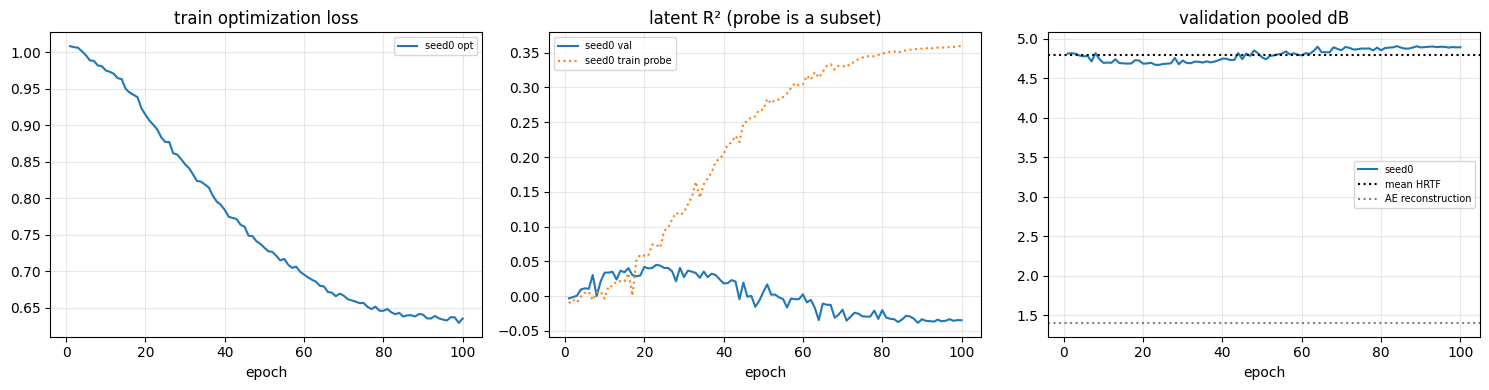

输出： /content/drive/MyDrive/HRTF_Checkpoints/mesh2z_direct_graph_rff_v1


In [ ]:
# Cell 10 — 验证结果、曲线、同 split 的 3_6 历史对照、导出
def show_rows(rows,title):
    print('\n'+title); print(f'{"":48s}{"R²(z)":>9s}{"pooled":>9s}{"6–12k":>9s}{"LSD":>9s}')
    for name,r in rows.items(): print(f'{name:48s}{r["r2"]:+9.4f}{r["db"]:9.3f}{r["db_notch"]:9.3f}{r["lsd"]:9.3f}')
clean=lambda r: {k:v for k,v in r.items() if k!='ear_mse'}
if RUNS:
    preds=[predict_rows(RUNS[f'seed{s}']['model'],S['val']) for s in CFG['SEEDS']]
    Zens=np.mean(preds,0); VAL_ROWS[f'{MODEL_LABEL}, seeds {CFG["SEEDS"]}']=dict(r2=r2z(Zens,Yva,my_tr),**score(Zens))
    if 'shuffled' in RUNS:
        zs=predict_rows(RUNS['shuffled']['model'],S['val']); VAL_ROWS[f'{MODEL_LABEL}, shuffled control']=dict(r2=r2z(zs,Yva,my_tr),**score(zs))
show_rows(VAL_ROWS,f'VALIDATION：{len(va_sub)} 人；全部面参与网络')
REF36=None; path36=os.path.join(SAVE_DIR,'mesh2z_fullmesh_v1','results.json')
if os.path.isfile(path36) and not CFG['SMOKE_N']:
    r36=json.load(open(path36))
    same=r36.get('mesh_zip_sha256')==MESH_ZIP_SHA256 and all(sorted(r36.get('split',{}).get(k,[]))==sorted(SPLIT[k]) for k in SPLIT)
    same=same and abs(r36['val']['population mean (train ears)']['db']-BASE['db'])<1e-3
    if same:
        REF36=r36['val']; print('\n3_6 已保存历史对照（同 source / split / baseline，未重训）：')
        for k in ['ridge · exact','MLP · exact · seeds [0]']:
            if k in REF36: print(k,REF36[k]['db'],'dB',REF36[k]['r2'],'R²(z)')
    else: print('3_6 来源、划分或 baseline 不一致；不作数值对照。')
PAIRED=[]
if RUNS:
    rng=np.random.default_rng(0); groups=np.arange(len(va_sub)); boot=rng.choice(groups,(CFG['N_BOOT'],len(groups)))
    ear_idx=np.stack([2*boot,2*boot+1],-1).reshape(CFG['N_BOOT'],-1)
    for name,r in VAL_ROWS.items():
        if not name.startswith('full mesh graph'): continue
        a,b=r['ear_mse'],BASE['ear_mse']; delta=np.sqrt(a.mean())-np.sqrt(b.mean())
        bt=np.sqrt(a[ear_idx].mean(1))-np.sqrt(b[ear_idx].mean(1)); ci=np.percentile(bt,[2.5,97.5])
        PAIRED.append(dict(model=name,delta_db=float(delta),ci=ci.tolist()))
        print(f'{name} vs mean HRTF: {delta:+.3f} dB, paired subject CI [{ci[0]:+.3f},{ci[1]:+.3f}]（验证选择未计入 CI）')
    fig,ax=plt.subplots(1,3,figsize=(15,4))
    for tag,r in RUNS.items():
        h=r['hist']; ax[0].plot([x['epoch'] for x in h],[x['train_loss_opt'] for x in h],label=tag+' opt')
        ev=[x for x in h if 'val_db' in x]
        ax[1].plot([x['epoch'] for x in ev],[x['val_r2'] for x in ev],label=tag+' val')
        ax[1].plot([x['epoch'] for x in ev],[x['train_probe_r2'] for x in ev],ls=':',label=tag+' train probe')
        ax[2].plot([x['epoch'] for x in ev],[x['val_db'] for x in ev],label=tag)
    ax[0].set_title('train optimization loss'); ax[1].set_title('latent R² (probe is a subset)'); ax[2].set_title('validation pooled dB')
    ax[2].axhline(BASE['db'],color='k',ls=':',label='mean HRTF'); ax[2].axhline(REC['db'],color='grey',ls=':',label='AE reconstruction')
    for a in ax:a.set_xlabel('epoch');a.grid(alpha=.3);a.legend(fontsize=7)
    plt.tight_layout();plt.savefig(os.path.join(OUT_DIR,'fullmesh_graph_curves.png'),dpi=150);plt.show()
report=dict(cfg=CFG,model_args=MODEL_ARGS,mesh_zip_sha256=MESH_ZIP_SHA256,ae_sha256=AE_SHA256,latent_sha256=LATENT_SHA,
            core_sha256=CORE_SHA256,split=SPLIT,pack_info=PACK_INFO,graph_meta=GRAPH_META,
            val={k:clean(v) for k,v in VAL_ROWS.items()},paired=PAIRED,reference36=REF36,
            runs={k:dict(best_epoch=v['best_epoch'],hist=v['hist']) for k,v in RUNS.items()},
            evaluation='Validation selection, not an independent final test; no claim of a geometry ceiling.')
tmp=os.path.join(OUT_DIR,'results.json.tmp');json.dump(report,open(tmp,'w'),indent=1,ensure_ascii=False,default=float);os.replace(tmp,os.path.join(OUT_DIR,'results.json'))
print('输出：',OUT_DIR)


In [ ]:
# Cell 11 — TEST 默认关闭；只有此处才使用 locked subjects 的目标/实测并评分
TEST_MARKS=[os.path.join(SAVE_DIR,'TEST_SPENT_SONICOM_locked36.json'),
            os.path.join(SAVE_DIR,'geometry2z_tvt_v1','TEST_SPENT_mesh.json'),
            os.path.join(SAVE_DIR,'geometry2z_tvt_v2','TEST_SPENT_mesh.json')]
if not CFG['RUN_TEST'] or CFG['SMOKE_N']:
    print('RUN_TEST=False：36 人未参与训练、验证或评分。')
else:
    assert RUNS and all(f'seed{s}' in RUNS for s in CFG['SEEDS']), '先完成训练和验证选择'
    assert not any(os.path.exists(p) for p in TEST_MARKS), '3_5 / 3_6 / 3_7 的共同测试集已经用过'
    # 先占用共同标记，避免评分后中断导致结果未记录又重跑。
    record=dict(state='started',notebook='FFM_3_7',time=time.strftime('%Y-%m-%d %H:%M:%S'),cfg=CFG)
    with open(TEST_MARKS[0],'x') as f:json.dump(record,f,indent=1)
    Zcache=L['Z_ear']; Yte=np.array([Zcache[SID_INDEX[s],sd].ravel() for s in LOCKED for sd in (0,1)]);del Zcache
    Xte=np.stack([load_ear(DIRS,s,sd) for s in LOCKED for sd in (0,1)]); sides=np.tile([0,1],len(LOCKED))
    zs=[]
    for seed in CFG['SEEDS']:
        m=RUNS[f'seed{seed}']['model'];m.eval();ps=[]
        with torch.no_grad():
            for s in LOCKED:
                V,ptr,nbr,canals=load_subject(s)
                for sd in (0,1):ps.append(m(V,ptr,nbr,canals[sd],sd).cpu().numpy())
                del V,ptr,nbr,canals
        zs.append(PCA.inverse(np.stack(ps)))
    Zp=np.mean(zs,0);base=hrtf_metrics(np.broadcast_to(MU,Xte.shape).astype(np.float32),Xte,sides);rec=hrtf_metrics(decode(Yte),Xte,sides)
    test={'population mean HRTF':dict(r2=0.,**base),
          MODEL_LABEL:dict(r2=r2z(Zp,Yte,my_tr),**hrtf_metrics(decode(Zp),Xte,sides,base['db'],rec['db'])),
          'AE reconstruction':dict(r2=1.,**rec)}
    show_rows(test,'LOCKED TEST：最终一次')
    record.update(state='complete',rows={k:clean(v) for k,v in test.items()})
    for p in [TEST_MARKS[0],os.path.join(OUT_DIR,'TEST_SPENT_mesh.json')]:
        with open(p+'.tmp','w') as f:json.dump(record,f,indent=1,default=float)
        os.replace(p+'.tmp',p)


RUN_TEST=False：36 人未参与训练、验证或评分。


## 怎么读这版的结果

- 这是从所有原三角面及逐顶点 RFF 训练的 graph encoder；不使用预先汇总的全表面 RFF 描述符。输出头仍是 MLP。
- RFF 频率属于输入增强层，固定 buffer 随 checkpoint 保存；实际学习的是 corner 编码器、图网络和输出头。
- 如果它只学会训练 probe、验证不提高，是这个网络/样本量下的泛化问题；如果 probe 也学不好，先排查优化和容量。
  probe 只有固定的训练子集，不把它说成完整训练 R²。
- Cell 8 必须报告 source face count 全部保留、最后一面有梯度。分块是内存策略，图消息仍能跨分块邻接；没有切断图边。
- 不因一个负结果宣布完整 mesh 没信息。对照的是同一数据、划分、目标输出空间和误差口径下的具体网络。
- 每个 epoch 的耗时/显存由真实 GPU 实测；本地交付检查不等于 Colab 上 100 epochs 已训练。
